# A2 - Processo completo do KDD

A A2 aproveita e melhora a A1 e conclui **entendimento, seleção, limpeza, transformação, mineração, avaliação, interpretação e aplicação/documentação**. A A1 entregue permanece preservada.

As decisões e alternativas estão em `docs/a2/Decisoes_KDD_Completo.md`; o relatório integrado reúne resultados e limites. O código abaixo chama a mesma biblioteca dos comandos de reprodução. O alvo é o rótulo registrado, sem validação clínica independente.

In [1]:
from pathlib import Path
import os, sys, json, subprocess
import pandas as pd
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT = next((p for p in candidates if (p / "pyproject.toml").is_file() and (p / "src/kdd_revision").is_dir()), None)
if PROJECT is None:
    raise RuntimeError("Abra o notebook dentro do clone Data-Mining.")
sys.path.insert(0, str(PROJECT / "src"))
SOURCE = Path(os.environ.get("KDD_SOURCE", str(PROJECT / "dados/raw/UCMF_raw.csv"))).expanduser()
if not SOURCE.is_file():
    raise FileNotFoundError("Disponibilize a base da disciplina em dados/raw/ ou defina KDD_SOURCE.")
print("Escopo: A2 com o processo completo do KDD; a A1 entregue é histórica.")

Escopo: A2 com o processo completo do KDD; a A1 entregue é histórica.


## Executar a sequência completa

A entrada e as regras são verificadas; limpeza e transformações são aplicadas. A busca compara 81 configurações por cenário, com imputação/vocabulário/escala ajustados em cada treino de fold. Há CV e nested CV no desenvolvimento. As escolhas são congeladas antes do teste histórico, que já passou por exploração.

Um clone sem artefatos executa toda a busca. Quando existe uma execução completa e compatível, `REUTILIZAR_BUSCA_CONGELADA=True` confere fonte, código de ajuste, protocolo, hashes e reaplicação dos modelos antes de reutilizá-la. A aplicação e os relatórios são atualizados sem tuning. Use False para refazer a busca, mantendo todos os critérios.

In [2]:
REUTILIZAR_BUSCA_CONGELADA = True
command = [sys.executable, str(PROJECT / "tools/run_full_kdd.py"), "--source", str(SOURCE)]
if REUTILIZAR_BUSCA_CONGELADA and (PROJECT / "artifacts/a2_mining/verification.json").exists():
    command.append("--reuse-mining")
completed = subprocess.run(command, cwd=PROJECT, capture_output=True, text=True, timeout=1800)
if completed.returncode:
    raise RuntimeError(completed.stderr + completed.stdout)
A = PROJECT / "artifacts/a2_mining"
verification = json.loads((A / "verification.json").read_text())
assert verification["complete"] and verification["all_selections_frozen_before_test"]
print({k: verification[k] for k in ["n_development", "n_test", "n_candidates_per_scenario", "n_preprocessing_fits_audited", "groups_crossing_fit_test"]})

{'n_development': 9361, 'n_test': 2342, 'n_candidates_per_scenario': 81, 'n_preprocessing_fits_audited': 252, 'groups_crossing_fit_test': 0}


## Avaliar a busca e os modelos

A média de CV usada para escolher é distinta da avaliação aninhada do procedimento e da avaliação secundária no teste histórico. Comparamos recall, precisão, especificidade, F1 e BA junto das contagens. Os gráficos não autorizam escolher um limiar pelo teste. Scores e associações não constituem diagnóstico ou causa.

,nested_BA,candidate,n,prevalence,tn,fp,fn,tp,recall,specificity,precision,f1,balanced_accuracy,roc_auc,average_precision,brier,accuracy
cenario,,,,,,,,,,,,,,,,,
A,0.919097,01_tree_347f3936,2342,0.42357,1310,40,111,881,0.888105,0.970370,0.956569,0.921066,0.929238,0.946402,0.934428,0.057300,0.935525
B,0.630871,75_forest_e81a70e9,2342,0.42357,927,423,379,613,0.617944,0.686667,0.591699,0.604536,0.652305,0.696217,0.637153,0.220336,0.657558
B_contexto,0.709586,80_forest_2ca7331d,2342,0.42357,1085,265,318,674,0.679435,0.803704,0.717785,0.698084,0.741570,0.810588,0.759401,0.178923,0.751067


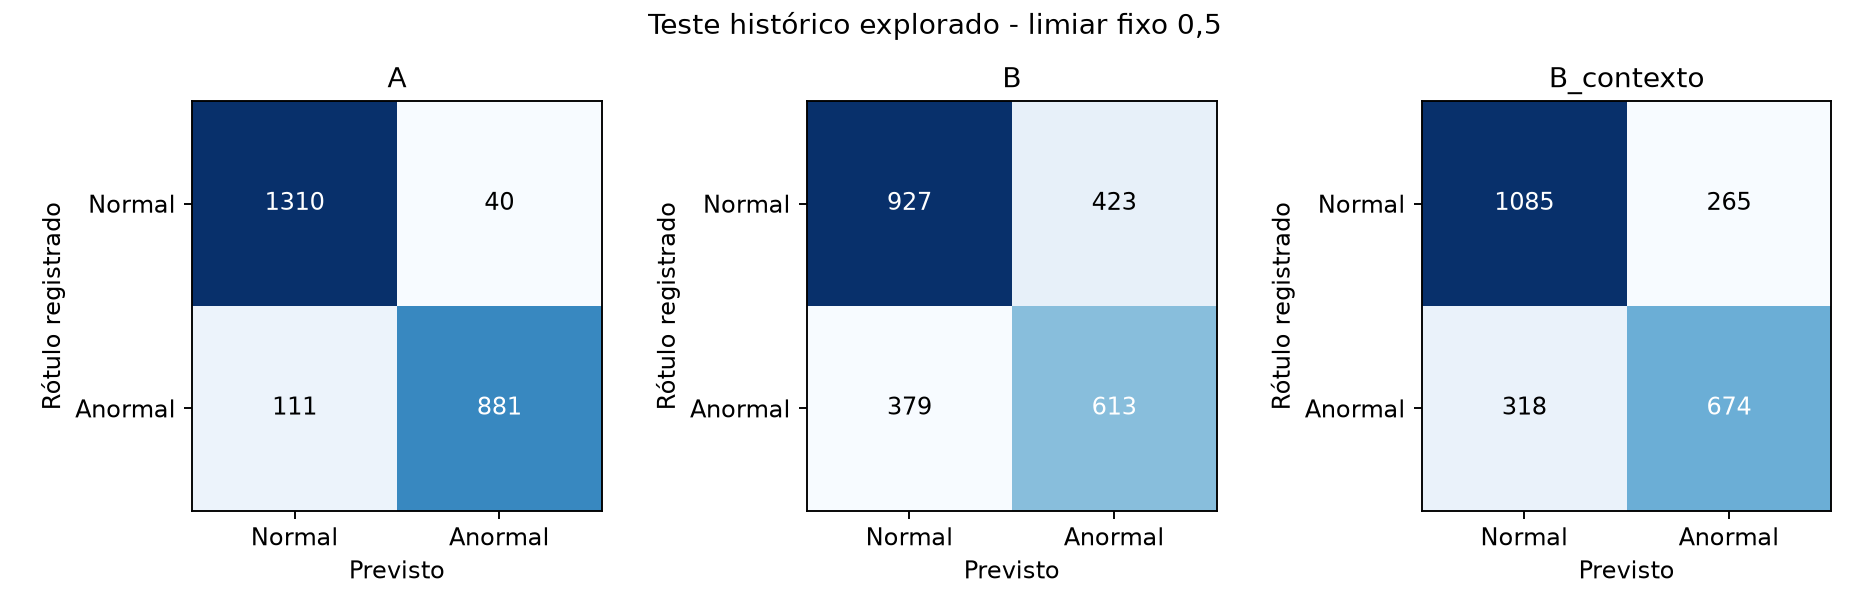

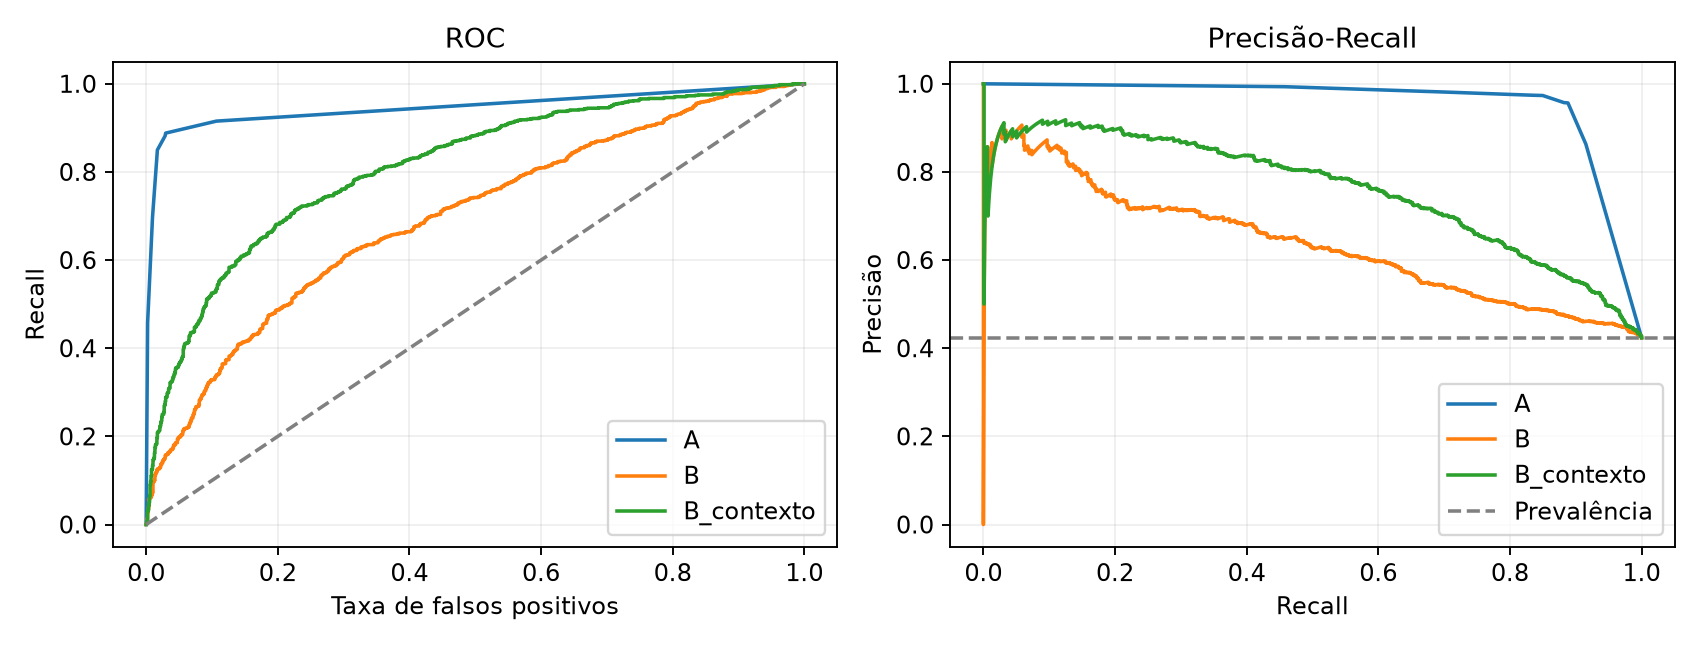

In [3]:
metrics = json.loads((A / "test_metrics.json").read_text())
nested = json.loads((A / "nested_results.json").read_text())
display(pd.DataFrame([{ "cenario": scenario, "nested_BA": nested[scenario]["pooled_oof"]["balanced_accuracy"], **result } for scenario, result in metrics.items()]).set_index("cenario"))
from IPython.display import display, Image
display(Image(filename=str(A / "figures/confusoes.png")))
display(Image(filename=str(A / "figures/curvas.png")))

## Contestar as escolhas

As sensibilidades comparam qualidade, indicadores, redução e balanceamento no desenvolvimento. PCA usa a melhor logística e precisa ser comparada à mesma configuração sem PCA. São explorações pós-seleção, sem trocar o vencedor pela pontuação do teste. Um ganho pequeno não comprova superioridade fora destes dados.

In [4]:
sensitivity = pd.read_csv(A / "sensibilidades.csv")
display(sensitivity.pivot(index="variant", columns="scenario", values="mean_cv_balanced_accuracy"))
importance = pd.read_csv(A / "importancia_permutacao.csv")
display(importance.sort_values(["scenario", "mean_drop_balanced_accuracy"], ascending=[True,False]).groupby("scenario").head(3))

scenario,A,B,B_contexto
variant,,,
PCA95_melhor_logistica,0.917371,0.615506,0.707107
principal,0.919407,0.634059,0.712799
sem_HDA2,0.919407,NaN,0.711553
sem_IMC,0.919407,0.636554,0.710349
sem_IMC_HDA2,0.919407,0.636554,0.710133
sem_PPA,0.919407,NaN,0.711227
sem_indicadores,0.919407,0.626721,0.711078
sobreamostragem,0.919407,0.633415,0.712807
subamostragem,0.919407,0.629265,0.711282


,scenario,variable,mean_drop_balanced_accuracy,sd_repeats,scope
10,A,SOPRO,0.392887,0.013355,development validation fold 0; exploratory pos...
9,A,B2,0.030955,0.002644,development validation fold 0; exploratory pos...
0,A,Peso,0.000000,0.000000,development validation fold 0; exploratory pos...
22,B,FC,0.048132,0.016063,development validation fold 0; exploratory pos...
16,B,Peso,0.024251,0.005032,development validation fold 0; exploratory pos...
19,B,IDADE,0.012972,0.005511,development validation fold 0; exploratory pos...
36,B_contexto,MOTIVO2,0.052925,0.005456,development validation fold 0; exploratory pos...
35,B_contexto,MOTIVO1,0.043411,0.009097,development validation fold 0; exploratory pos...
32,B_contexto,HDA 1,0.012925,0.002180,development validation fold 0; exploratory pos...


## Aplicar o conhecimento, respeitando o suporte dos dados

A aplicação inicial que exigia apenas um campo foi rejeitada: muitos padrões de ausência não tinham suporte no desenvolvimento. A regra revisada exige padrão de disponibilidade presente em pelo menos 30 exemplos e categorias conhecidas. Coberturas para 1/10/30 são publicadas; não há rótulos novos para escolher uma acurácia ótima. Cobertura aceita não valida a previsão individual.

As previsões ficam locais e separadas de y. O conhecimento também orienta corrigir a coleta e esclarecer temporalidade e construção do alvo. Nenhuma implantação clínica foi feita.

In [5]:
application = json.loads((PROJECT / "artifacts/a2_application/summary.json").read_text())
display(pd.DataFrame([{ "cenario": scenario, **{k: value[k] for k in ["n_unlabeled", "n_scored", "n_abstained", "n_p_ge_half"]} } for scenario,value in application.items()]))
display(pd.read_csv(PROJECT / "artifacts/a2_application/comparacao_cobertura.csv"))
reproduction = json.loads((PROJECT / "artifacts/a2_kdd/reproduction.json").read_text())
assert reproduction["complete"] and reproduction["test_membership_unchanged"]
assert all(r["identical_classes"] and r["max_abs_prediction_difference"] <= 1e-12 for r in reproduction["models_reapplied"].values())
print("Modelos salvos reaplicados e métricas conferidas; fonte preservada.")
print("Relatório: docs/a2/Relatorio_A2_KDD_Completo.pdf")
print("Decisões: docs/a2/Decisoes_KDD_Completo.md e Registro_Microdecisoes.csv")

,cenario,n_unlabeled,n_scored,n_abstained,n_p_ge_half
0,A,1169,19,1150,6
1,B,1169,380,789,158
2,B_contexto,1169,294,875,81


,scenario,minimum_pattern_support,n_accepted,n_abstained,n_unknown_category
0,A,1,308,861,0
1,A,10,21,1148,0
2,A,30,19,1150,0
3,B,1,425,744,0
4,B,10,394,775,0
5,B,30,380,789,0
6,B_contexto,1,412,757,0
7,B_contexto,10,341,828,0
8,B_contexto,30,294,875,0


Modelos salvos reaplicados e métricas conferidas; fonte preservada.
Relatório: docs/a2/Relatorio_A2_KDD_Completo.pdf
Decisões: docs/a2/Decisoes_KDD_Completo.md e Registro_Microdecisoes.csv
